<a href="https://colab.research.google.com/github/aryananand0/Math-344-Lab-Project-Fall-2026/blob/main/Notebooks/05_hero_figure.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Milestone 5: Comparing the Movie Rating Models

I put the test errors from Milestones 2 and 3 in one chart so it's easy to see how the models did on the same hidden ratings.

In [1]:
from pathlib import Path
import subprocess
import sys

# Use the local files if I opened the notebook from my checkout
repo = Path.cwd()
if not (repo / "Src").is_dir():
    repo = repo.parent
if not (repo / "Src").is_dir():
    repo = Path("Math-344-Lab-Project-Fall-2026")
    if not (repo / "Src").is_dir():
        subprocess.run(
            ["git", "clone", "-q", "https://github.com/aryananand0/Math-344-Lab-Project-Fall-2026.git", str(repo)],
            check=True
        )

sys.path.insert(0, str(repo.resolve() / "Src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from evaluate import rmse, split_ratings, to_matrix
from models import baseline_matrix

In [2]:
import urllib.request
import zipfile

# Download MovieLens if the ratings file is missing
if not Path("ml-100k/u.data").is_file():
    urllib.request.urlretrieve(
        "https://files.grouplens.org/datasets/movielens/ml-100k.zip",
        "ml-100k.zip"
    )
    with zipfile.ZipFile("ml-100k.zip") as zipped:
        zipped.extractall()

ratings = pd.read_csv(
    "ml-100k/u.data", sep="\t",
    names=["user", "item", "rating", "time"]
)

# Check the split and baseline against notebooks 02 and 03
train, test = split_ratings(ratings)
B = baseline_matrix(to_matrix(train))
u = test["user"].to_numpy() - 1
i = test["item"].to_numpy() - 1
truth = test["rating"].to_numpy()

n_test = len(test)
base_error = round(rmse(np.clip(B[u, i], 1, 5), truth), 4)
assert (n_test, base_error) == (9968, 0.9545), "Check the split in notebooks 02 and 03."

print("train:", len(train), "test:", n_test)
print("baseline test RMSE:", base_error)

train: 90032 test: 9968
baseline test RMSE: 0.9545


I checked the test set size and the user + movie baseline with the same functions as before. Lower RMSE means the predictions were closer to the hidden star ratings.

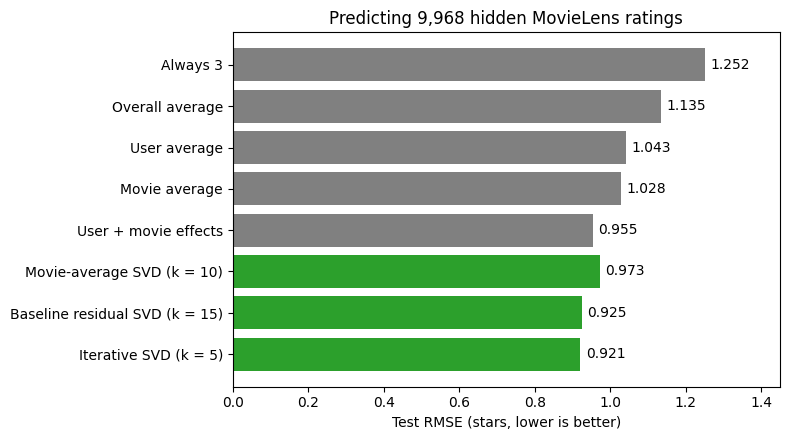

Validation-chosen Model 2 reduced RMSE by 3.1%.


In [3]:
# Baseline scores from notebook 02 and SVD scores from notebook 03
results = {
    "Always 3": 1.2516,
    "Overall average": 1.1349,
    "User average": 1.0426,
    "Movie average": 1.0284,
    "User + movie effects": base_error,
    "Movie-average SVD (k = 10)": 0.9726,
    "Baseline residual SVD (k = 15)": 0.9250,
    "Iterative SVD (k = 5)": 0.9206,
}

# Keep the SVD models green and the average-based models gray
colors = ["tab:green" if "SVD" in model else "gray" for model in results]
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh(list(results), list(results.values()), color=colors)
ax.bar_label(bars, fmt="%.3f", padding=4)
ax.invert_yaxis()
ax.set_xlabel("Test RMSE (stars, lower is better)")
ax.set_title(f"Predicting {n_test:,} hidden MovieLens ratings")
ax.set_xlim(0, 1.45)
fig.tight_layout()
fig.savefig(repo / "Figures" / "hero.png", dpi=150)
plt.show()

improvement = 100 * (base_error - results["Baseline residual SVD (k = 15)"]) / base_error
print(f"Validation-chosen Model 2 reduced RMSE by {improvement:.1f}%.")

## What we found

The rank-15 model picked on validation data scored 0.9250 stars on the test set, about 3.1% lower than the 0.9545 baseline. Iterative SVD scored 0.9206 after 15 rounds at k = 5. I picked that rank by looking at the test scores.